<center><img src="/image/dataset-cover.jpg" width=500></center>


Insurance companies invest a lot of time and money into optimizing their pricing and accurately estimating the likelihood that customers will make a claim. In many countries insurance it is a legal requirement to have car insurance in order to drive a vehicle on public roads, so the market is very large!

(`Source: https://www.accenture.com/_acnmedia/pdf-84/accenture-machine-leaning-insurance.pdf`) 

Knowing all of this, On the Road car insurance have requested your services in building a model to predict whether a customer will make a claim on their insurance during the policy period. As they have very little expertise and infrastructure for deploying and monitoring machine learning models, they've asked you to identify the single feature that results in the best performing model, as measured by accuracy, so they can start with a simple model in production.

They have supplied you with their customer data as a csv file called `car_insurance.csv`, along with a table detailing the column names and descriptions below.



## The dataset

| Column | Description |
|--------|-------------|
| `id` | Unique client identifier |
| `age` | Client's age: <br> <ul><li>`0`: 16-25</li><li>`1`: 26-39</li><li>`2`: 40-64</li><li>`3`: 65+</li></ul> |
| `gender` | Client's gender: <br> <ul><li>`0`: Female</li><li>`1`: Male</li></ul> |
| `driving_experience` | Years the client has been driving: <br> <ul><li>`0`: 0-9</li><li>`1`: 10-19</li><li>`2`: 20-29</li><li>`3`: 30+</li></ul> |
| `education` | Client's level of education: <br> <ul><li>`0`: No education</li><li>`1`: High school</li><li>`2`: University</li></ul> |
| `income` | Client's income level: <br> <ul><li>`0`: Poverty</li><li>`1`: Working class</li><li>`2`: Middle class</li><li>`3`: Upper class</li></ul> |
| `credit_score` | Client's credit score (between zero and one) |
| `vehicle_ownership` | Client's vehicle ownership status: <br><ul><li>`0`: Does not own their vehilce (paying off finance)</li><li>`1`: Owns their vehicle</li></ul> |
| `vehcile_year` | Year of vehicle registration: <br><ul><li>`0`: Before 2015</li><li>`1`: 2015 or later</li></ul> |
| `married` | Client's marital status: <br><ul><li>`0`: Not married</li><li>`1`: Married</li></ul> |
| `children` | Client's number of children |
| `postal_code` | Client's postal code | 
| `annual_mileage` | Number of miles driven by the client each year |
| `vehicle_type` | Type of car: <br> <ul><li>`0`: Sedan</li><li>`1`: Sports car</li></ul> |
| `speeding_violations` | Total number of speeding violations received by the client | 
| `duis` | Number of times the client has been caught driving under the influence of alcohol |
| `past_accidents` | Total number of previous accidents the client has been involved in |
| `outcome` | Whether the client made a claim on their car insurance (response variable): <br><ul><li>`0`: No claim</li><li>`1`: Made a claim</li></ul> |

In [2]:
# Import required modules
import pandas as pd

# Start coding!
df = pd.read_csv(r'C:\Users\halmu\Downloads\Car_Insurance3\data\raw\car_insurance.csv')
df.head()

,id,age,gender,driving_experience,education,income,credit_score,vehicle_ownership,vehicle_year,married,children,postal_code,annual_mileage,vehicle_type,speeding_violations,duis,past_accidents,outcome
0,569520,3,0,0-9y,high school,upper class,0.629027,1.0,after 2015,0.0,1.0,10238,12000.0,sedan,0,0,0,0.0
1,750365,0,1,0-9y,none,poverty,0.357757,0.0,before 2015,0.0,0.0,10238,16000.0,sedan,0,0,0,1.0
2,199901,0,0,0-9y,high school,working class,0.493146,1.0,before 2015,0.0,0.0,10238,11000.0,sedan,0,0,0,0.0
3,478866,0,1,0-9y,university,working class,0.206013,1.0,before 2015,0.0,1.0,32765,11000.0,sedan,0,0,0,0.0
4,731664,1,1,10-19y,none,working class,0.388366,1.0,before 2015,0.0,0.0,32765,12000.0,sedan,2,0,1,1.0


In [3]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   10000 non-null  int64  
 1   age                  10000 non-null  int64  
 2   gender               10000 non-null  int64  
 3   driving_experience   10000 non-null  str    
 4   education            10000 non-null  str    
 5   income               10000 non-null  str    
 6   credit_score         9018 non-null   float64
 7   vehicle_ownership    10000 non-null  float64
 8   vehicle_year         10000 non-null  str    
 9   married              10000 non-null  float64
 10  children             10000 non-null  float64
 11  postal_code          10000 non-null  int64  
 12  annual_mileage       9043 non-null   float64
 13  vehicle_type         10000 non-null  str    
 14  speeding_violations  10000 non-null  int64  
 15  duis                 10000 non-null  int64  
 16

,id,age,gender,credit_score,vehicle_ownership,married,children,postal_code,annual_mileage,speeding_violations,duis,past_accidents,outcome
count,10000.000000,10000.000000,10000.000000,9018.000000,10000.000000,10000.000000,10000.000000,10000.000000,9043.000000,10000.000000,10000.00000,10000.000000,10000.000000
mean,500521.906800,1.489500,0.499000,0.515813,0.697000,0.498200,0.688800,19864.548400,11697.003207,1.482900,0.23920,1.056300,0.313300
std,290030.768758,1.025278,0.500024,0.137688,0.459578,0.500022,0.463008,18915.613855,2818.434528,2.241966,0.55499,1.652454,0.463858
min,101.000000,0.000000,0.000000,0.053358,0.000000,0.000000,0.000000,10238.000000,2000.000000,0.000000,0.00000,0.000000,0.000000
25%,249638.500000,1.000000,0.000000,0.417191,0.000000,0.000000,0.000000,10238.000000,10000.000000,0.000000,0.00000,0.000000,0.000000
50%,501777.000000,1.000000,0.000000,0.525033,1.000000,0.000000,1.000000,10238.000000,12000.000000,0.000000,0.00000,0.000000,0.000000
75%,753974.500000,2.000000,1.000000,0.618312,1.000000,1.000000,1.000000,32765.000000,14000.000000,2.000000,0.00000,2.000000,1.000000
max,999976.000000,3.000000,1.000000,0.960819,1.000000,1.000000,1.000000,92101.000000,22000.000000,22.000000,6.00000,15.000000,1.000000


In [4]:
# check for missing values
missing_data = df.isnull().sum()
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_df = pd.DataFrame({'Missing Count': missing_data, 'Percentage (%)': missing_percentage})
print(missing_df[missing_df['Missing Count'] > 0])

# impute the median for numerical columns and fill missing values (الطريقة المُحسّنة والآمنة)
df['credit_score'] = df['credit_score'].fillna(df['credit_score'].median())
df['annual_mileage'] = df['annual_mileage'].fillna(df['annual_mileage'].median())

                Missing Count  Percentage (%)
credit_score              982            9.82
annual_mileage            957            9.57


Outcome Distribution (%):
outcome
0.0    68.67
1.0    31.33
Name: proportion, dtype: float64


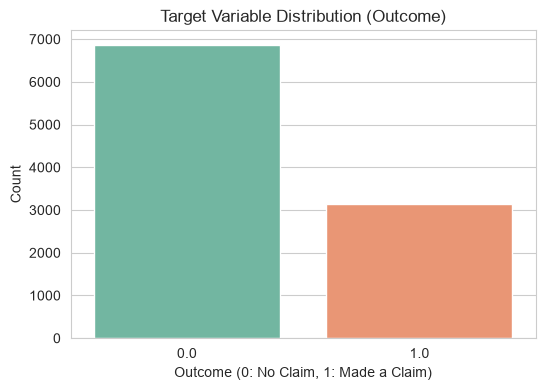

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# outcome distribution with percentage
outcome_counts = df['outcome'].value_counts(normalize=True) * 100
print("Outcome Distribution (%):")
print(outcome_counts)

# plot the distribution of the target variable (outcome)
plt.figure(figsize=(6, 4))

# set the style of the plot
sns.set_style('whitegrid')
sns.countplot(x='outcome', data=df, hue='outcome', palette='Set2', legend=False)

plt.title('Target Variable Distribution (Outcome)')
plt.xlabel('Outcome (0: No Claim, 1: Made a Claim)')
plt.ylabel('Count')
plt.show()

In [6]:
# Check for categorical/text columns safely
categorical_cols = df.select_dtypes(include=['object', 'string']).columns
print("Categorical Columns:", categorical_cols)

# Apply One-Hot Encoding with get_dummies
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

Categorical Columns: Index(['driving_experience', 'education', 'income', 'vehicle_year',
       'vehicle_type'],
      dtype='str')


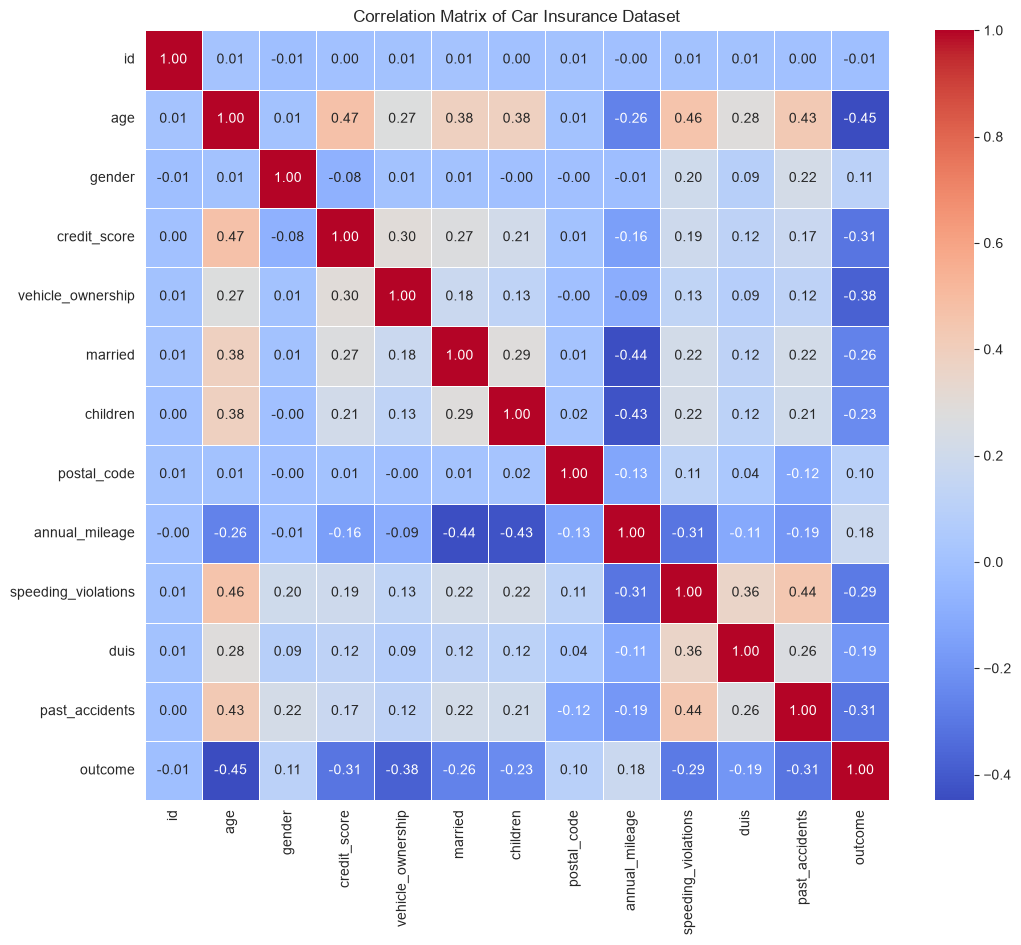

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 10))

# Calculate correlation matrix using only numeric columns to avoid string conversion errors
correlation_matrix = df.corr(numeric_only=True)

sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix of Car Insurance Dataset')
plt.show()

In [8]:
# تطبيق One-Hot Encoding على الأعمدة الفئوية
categorical_cols = ['driving_experience', 'education', 'income', 'vehicle_year', 'vehicle_type']
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

# التأكد من أن جميع الأعمدة أصبحت رقمية
print(df_encoded.info())

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id                         10000 non-null  int64  
 1   age                        10000 non-null  int64  
 2   gender                     10000 non-null  int64  
 3   credit_score               10000 non-null  float64
 4   vehicle_ownership          10000 non-null  float64
 5   married                    10000 non-null  float64
 6   children                   10000 non-null  float64
 7   postal_code                10000 non-null  int64  
 8   annual_mileage             10000 non-null  float64
 9   speeding_violations        10000 non-null  int64  
 10  duis                       10000 non-null  int64  
 11  past_accidents             10000 non-null  int64  
 12  outcome                    10000 non-null  float64
 13  driving_experience_10-19y  10000 non-null  bool   
 14  dr

In [9]:
# Apply One-Hot Encoding to categorical columns and drop the first dummy to avoid multicollinearity
categorical_cols = ['driving_experience', 'education', 'income', 'vehicle_year', 'vehicle_type']
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

# Verify that all columns have been successfully converted and check data types
print(df_encoded.info())

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id                         10000 non-null  int64  
 1   age                        10000 non-null  int64  
 2   gender                     10000 non-null  int64  
 3   credit_score               10000 non-null  float64
 4   vehicle_ownership          10000 non-null  float64
 5   married                    10000 non-null  float64
 6   children                   10000 non-null  float64
 7   postal_code                10000 non-null  int64  
 8   annual_mileage             10000 non-null  float64
 9   speeding_violations        10000 non-null  int64  
 10  duis                       10000 non-null  int64  
 11  past_accidents             10000 non-null  int64  
 12  outcome                    10000 non-null  float64
 13  driving_experience_10-19y  10000 non-null  bool   
 14  dr

In [10]:
import os

# Create the processed data directory if it doesn't exist
os.makedirs('../data/processed', exist_ok=True)

# save the processed DataFrame to a CSV file
df_encoded.to_csv('../data/processed/car_insurance_encoded.csv', index=False)

print("Processed data saved successfully in the data/processed directory!")

Processed data saved successfully in the data/processed directory!
